# Optimal price under constant elasticity

**Question.** Which weekly price maximises expected profit for each product, given an elasticity and a cost assumption, and how sensitive is that answer?

**Inputs.**
- Elasticity by product price tier, re-estimated with `dp_elasticity` (see the DP01 repo, tag `v0.1.0`).
- Unit cost is **not in the data**. It is assumed to be a share of each product's median weekly price.
- Recommendations are restricted to each product's observed weekly price band (5th to 95th percentile).

**Formula.** With `q = q0 (p/p0)^ε` and `ε < −1`, profit is maximised at `p* = ε/(1+ε)·c`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from dp_elasticity.data import load_transactions, weekly_panel
from dp_elasticity.model import estimate_elasticity, segment_elasticities
from dp_pricing.optimal import expected_profit, optimal_price, product_bands, recommend

RAW = Path("../data/raw/online_retail.csv")
FIG = Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)
BASE_COST_SHARE = 0.6
sns.set_theme(style="whitegrid")

## 1. Panel and elasticities

In [2]:
tx = load_transactions(RAW)
panel = weekly_panel(tx, min_weeks=30)
pooled = estimate_elasticity(panel)
seg = segment_elasticities(panel)
print(f"pooled ε = {pooled.elasticity:.3f} [{pooled.ci_low:.3f}, {pooled.ci_high:.3f}]")
seg

pooled ε = -2.048 [-2.097, -1.998]


,tier,elasticity,ci_low,ci_high,n_products,n_obs
0,0,-1.943123,-1.998655,-1.887590,410,17991
1,1,-2.142845,-2.201855,-2.083835,410,17892
2,2,-2.511679,-2.579000,-2.444359,409,18044
3,3,-1.672698,-1.843015,-1.502381,410,18033


Each product gets its tier's elasticity. The tier is the quartile of mean log price, the same rule as `segment_elasticities`.

In [3]:
product_price = panel.groupby("StockCode")["log_p"].mean()
tiers = pd.qcut(product_price, 4, labels=False, duplicates="drop")
tier_eps = seg.set_index("tier")["elasticity"]
product_eps = tiers.map(tier_eps).dropna()

bands = product_bands(panel).loc[product_eps.index]
print(f"products with a tier elasticity: {len(bands)}")
bands.describe().round(2)

products with a tier elasticity: 1639


,p0,q0,p_min,p_max
count,1639.00,1639.00,1639.00,1639.00
mean,3.01,39.64,2.52,5.33
std,5.92,68.62,4.35,28.34
min,0.04,1.00,0.04,0.12
25%,0.95,7.50,0.80,1.63
50%,1.74,17.00,1.50,2.84
75%,3.75,41.00,2.95,5.48
max,201.52,916.00,135.05,876.28


## 2. Recommendations at the base cost assumption

In [4]:
base = recommend(bands, product_eps, cost_share=BASE_COST_SHARE)
base = base.assign(tier=tiers.reindex(base.index).astype(int))
base["price_multiple"] = base["price"] / base["p0"]

summary = (
    base.groupby("tier")
    .agg(
        products=("price", "size"),
        elasticity=("elasticity", "first"),
        median_price_multiple=("price_multiple", "median"),
        share_clipped=("clipped", "mean"),
        median_uplift=("uplift", "median"),
    )
    .round(3)
)
summary

,products,elasticity,median_price_multiple,share_clipped,median_uplift
tier,,,,,
0,410,-1.943,1.236,0.276,0.053
1,410,-2.143,1.125,0.144,0.020
2,409,-2.512,0.997,0.098,0.000
3,410,-1.673,1.412,0.576,0.140


Clipping means the unconstrained optimum falls outside the product's observed price band. Those recommendations are extrapolations and are flagged.

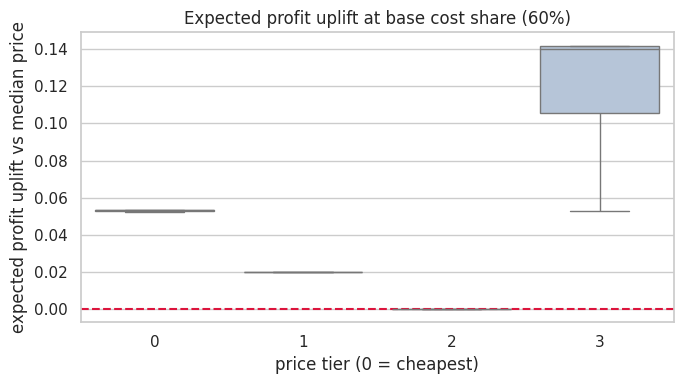

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=base, x="tier", y="uplift", color="lightsteelblue", ax=ax, showfliers=False)
ax.axhline(0, color="crimson", ls="--")
ax.set_xlabel("price tier (0 = cheapest)")
ax.set_ylabel("expected profit uplift vs median price")
ax.set_title(f"Expected profit uplift at base cost share ({BASE_COST_SHARE:.0%})")
fig.tight_layout()
fig.savefig(FIG / "uplift_by_tier.png", dpi=150)
plt.show()

## 3. Profit curve for one product

The highest-revenue product in tier 1 illustrates the curve. The dashed line is the optimum. The shaded area is the observed band.

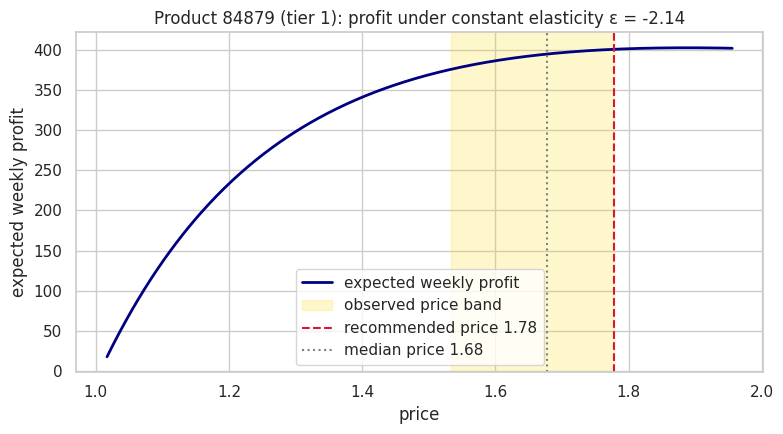

In [6]:
example = base[base["tier"] == 1].sort_values("profit_now", ascending=False).index[0]
row = base.loc[example]
prices = np.linspace(row["unit_cost"] * 1.01, bands.loc[example, "p_max"] * 1.1, 400)
profits = [expected_profit(p, row["unit_cost"], row["p0"], bands.loc[example, "q0"], row["elasticity"]) for p in prices]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(prices, profits, color="navy", lw=2, label="expected weekly profit")
ax.axvspan(bands.loc[example, "p_min"], bands.loc[example, "p_max"], color="gold", alpha=0.2, label="observed price band")
ax.axvline(row["price"], color="crimson", ls="--", label=f"recommended price {row['price']:.2f}")
ax.axvline(row["p0"], color="gray", ls=":", label=f"median price {row['p0']:.2f}")
ax.set_xlabel("price")
ax.set_ylabel("expected weekly profit")
ax.set_title(f"Product {example} (tier 1): profit under constant elasticity ε = {row['elasticity']:.2f}")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "profit_curve_example.png", dpi=150)
plt.show()

## 4. Sensitivity to cost and elasticity

Cost share is the main assumption. Changing it moves the optimum for every product in the same direction.
The table shows the median price multiple and the median uplift per tier across cost shares.

In [7]:
rows = []
for share in [0.5, 0.6, 0.7]:
    r = recommend(bands, product_eps, cost_share=share)
    r = r.assign(tier=tiers.reindex(r.index).astype(int), multiple=lambda d: d["price"] / d["p0"])
    for tier, sub in r.groupby("tier"):
        rows.append(
            {
                "cost_share": share,
                "tier": tier,
                "median_price_multiple": sub["multiple"].median(),
                "median_uplift": sub["uplift"].median(),
                "share_clipped": sub["clipped"].mean(),
            }
        )
sens = pd.DataFrame(rows)
sens.pivot(index="tier", columns="cost_share", values="median_price_multiple").round(3)

cost_share,0.5,0.6,0.7
tier,,,
0,1.030,1.236,1.442
1,0.938,1.125,1.313
2,0.879,0.997,1.163
3,1.243,1.412,1.412


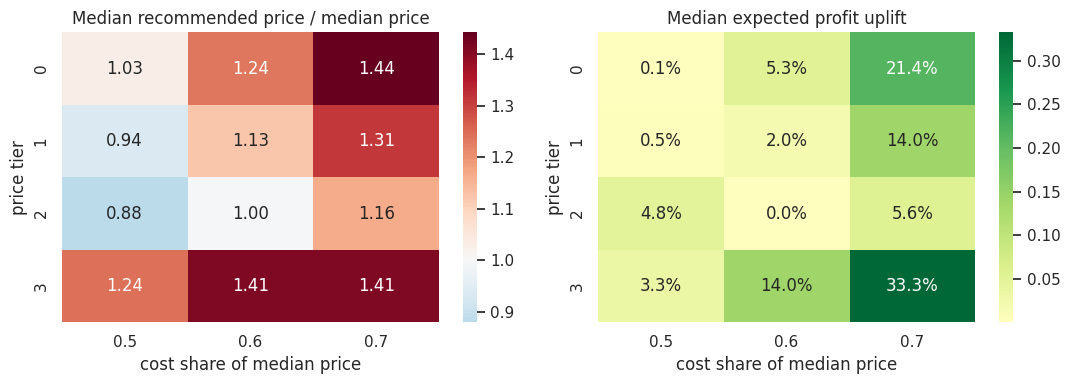

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
mult = sens.pivot(index="tier", columns="cost_share", values="median_price_multiple")
upl = sens.pivot(index="tier", columns="cost_share", values="median_uplift")
sns.heatmap(mult, annot=True, fmt=".2f", cmap="RdBu_r", center=1.0, ax=axes[0])
axes[0].set_title("Median recommended price / median price")
sns.heatmap(upl, annot=True, fmt=".1%", cmap="RdYlGn", center=0.0, ax=axes[1])
axes[1].set_title("Median expected profit uplift")
for ax in axes:
    ax.set_xlabel("cost share of median price")
    ax.set_ylabel("price tier")
fig.tight_layout()
fig.savefig(FIG / "sensitivity_heatmaps.png", dpi=150)
plt.show()

## 5. Elasticity uncertainty

The tier estimates have confidence intervals. Using the interval bounds in place of the point estimate shows how much the recommended multiple can move.

In [9]:
ci_rows = []
for label, col in [("CI low", "ci_low"), ("point", "elasticity"), ("CI high", "ci_high")]:
    eps_map = tiers.map(seg.set_index("tier")[col]).dropna()
    r = recommend(bands.loc[eps_map.index], eps_map, cost_share=BASE_COST_SHARE)
    r = r.assign(tier=tiers.reindex(r.index).astype(int), multiple=lambda d: d["price"] / d["p0"])
    ci_rows.append({"elasticity_used": label, "median_price_multiple": r["multiple"].median(), "median_uplift": r["uplift"].median()})
pd.DataFrame(ci_rows).round(3)

,elasticity_used,median_price_multiple,median_uplift
0,CI low,1.099,0.013
1,point,1.125,0.020
2,CI high,1.154,0.028


## 6. Summary

- At a 60% cost share, the median recommended price is about 1.24x the median price in tier 0 and 1.41x in tier 3. Tier 2 (the most elastic) stays at about 1.00x. Tier 1 is at about 1.13x.
- Median expected profit uplift at 60% cost is small: 0% to 5% in tiers 0 to 2, and 14% in tier 3. Tier 3 is also the most clipped (58% of products hit the top of their observed band), so its uplift is the least reliable. At 70% cost the uplifts rise to 21% (tier 0) and 33% (tier 3), so the uplift is very sensitive to the cost assumption.
- The recommended multiple rises with the cost share in every tier (for example, tier 0 goes from 1.03x at 50% to 1.44x at 70%). Cost is an assumption, so this is the main source of uncertainty.
- Elasticity CI bounds move the median multiple only slightly (1.10x to 1.15x), so the cost assumption dominates.
- The optimum depends on two unobserved inputs: the cost share (assumed) and the causal elasticity (not identified; see DP01). Treat the output as a sensitivity map, not a price to deploy.

In [10]:
summary

,products,elasticity,median_price_multiple,share_clipped,median_uplift
tier,,,,,
0,410,-1.943,1.236,0.276,0.053
1,410,-2.143,1.125,0.144,0.020
2,409,-2.512,0.997,0.098,0.000
3,410,-1.673,1.412,0.576,0.140
